# BASELINE: huấn luyện chỉ trên level 0

Đây là **bản gốc dùng làm đối chứng** cho báo cáo. Agent chỉ được huấn luyện ở level 0 (một thế cố định), sau đó đánh giá ở cả 3 level.

**Kết quả đã lưu trong output của notebook này (lần chạy gốc, 500 ván, seed 0):** level 0: 98,4%, level 1: 68,6%, level 2: 70,4% chiếu hết (bot ngẫu nhiên: 0,8% / 2,4% / 0,8%; bot tham lam: 5,0% / 12,6% / 9,4%).

**Cách chạy lại (xem `README_baseline.md`):**
1. Tạo thư mục `KHDL_baseline/checkpoints` trên Drive, tải `kqk.ipynb` (cùng thư mục với file này) vào đó.
2. **Restart runtime** (Runtime → Restart session), bật GPU, rồi chạy từ ô đầu.
3. Checkpoint lưu với tag `baseline_L0`, nằm riêng trong `KHDL_baseline/`, không ảnh hưởng thư mục `KHDL` hiện tại.


In [ ]:
!pip install -q chess
!jupyter nbconvert --to python "/content/drive/MyDrive/KHDL_baseline/checkpoints/kqk.ipynb"

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
[NbConvertApp] WARNING | pattern '/content/drive/MyDrive/KHDL_baseline/checkpoints/kqk.ipynb' matched no files
This application is used to convert notebook files (*.ipynb)
        to various other formats.


Options
The options below are convenience aliases to configurable class-options,
as listed in the "Equivalent to" description-line of the aliases.
To see all configurable class-options for some <cmd>, use:
    <cmd> --help-all

--debug
    set log level to logging.DEBUG (maximize logging output)
    Equivalent to: [--Application.log_level=10]
--show-config
    Show the application's configuration (human-readable format)
    Equivalent to: [--Application.show_config=True]
--show-config-json
    Show the application's configuration (json format)
    Equivalent to: [--Application.show_config_json=True]
--generate-config
    generate default config file

In [ ]:
import os, sys, json, time, random, importlib
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from google.colab import drive
drive.mount("/content/drive")

PROJECT_DIR = "/content/drive/MyDrive/KHDL_baseline"
CKPT_DIR = os.path.join(PROJECT_DIR, "checkpoints")
os.makedirs(CKPT_DIR, exist_ok=True)

KQK_IPYNB = os.path.join(CKPT_DIR, "kqk_v1.ipynb")
KQK_FILE = os.path.join(CKPT_DIR, "kqk_v1.py")

if not os.path.exists(KQK_IPYNB):
    raise FileNotFoundError(
        f"Không tìm thấy notebook: {KQK_IPYNB}. "
        "Hãy kiểm tra lại tên file và thư mục."
    )

!jupyter nbconvert --to python "/content/drive/MyDrive/KHDL_baseline/checkpoints/kqk.ipynb"

if not os.path.exists(KQK_FILE):
    raise FileNotFoundError(
        f"Chuyển đổi thất bại, không tìm thấy: {KQK_FILE}"
    )

if PROJECT_DIR not in sys.path:
    sys.path.insert(0, PROJECT_DIR)

if CKPT_DIR not in sys.path:
    sys.path.insert(0, CKPT_DIR)

sys.modules.pop("kqk", None)
import kqk
importlib.reload(kqk)

print("Đã nạp module:", kqk.__file__)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Thiết bị:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


Mounted at /content/drive
[NbConvertApp] Converting notebook /content/drive/MyDrive/KHDL_baseline/checkpoints/kqk.ipynb to python
[NbConvertApp] Writing 10638 bytes to /content/drive/MyDrive/KHDL_baseline/checkpoints/kqk.py
. . . . . . . .
. . . . . . . .
. . . . . . . .
. . . . k . . .
. . . . . . . .
. . . . . . . .
. . . . . . . .
. . . Q K . . .
(3, 8, 8) [1. 1. 1.]
292 e1e5 21
. . . . . . Q .
. . . k . . . .
. . . . . . . .
. K . . . . . .
. . . . . . . .
. . . . . . . .
. . . . . . . .
. . . . . . . .
Potential của vị trí ban đầu: 0.286
. . . . . . . .
. . . . . . . .
. . . . . . . .
. . . . k . . .
. . . . . . . .
. . . . . . . .
. . . . . . . .
. . . Q K . . .
(3, 8, 8) [1. 1. 1.]
292 e1e5 21
. . . . . . Q .
. . . k . . . .
. . . . . . . .
. K . . . . . .
. . . . . . . .
. . . . . . . .
. . . . . . . .
. . . . . . . .
Potential của vị trí ban đầu: 0.286
Đã nạp module: /content/drive/MyDrive/KHDL_baseline/checkpoints/kqk.py
Thiết bị: cuda
GPU: Tesla T4


In [ ]:
CONFIG = dict(
    seed=0,
    train_level=0,
    max_moves=50,
    num_episodes=15_000,

    gamma=0.95,
    lr=2e-4,
    batch_size=64,
    buffer_size=50_000,
    learn_start=1_000,
    tau=0.005,
    grad_clip=10.0,
    double_dqn=True,

    eps_start=1.0,
    eps_end=0.05,
    eps_decay_steps=80_000,
    explore_mate_in_one=True,

    eval_every=500,
    eval_games=500,
    eval_level=0,
    extra_eval_level=2,
    eval_seed=10_000,

    win_reward=5.0,
    lose_queen_reward=-0.3,
    stalemate_reward=-0.5,
    shaping_weight=0.3,

    resume=False,
    init_from=None,
)
print(json.dumps(CONFIG, indent=1))

{
 "seed": 0,
 "train_level": 0,
 "max_moves": 50,
 "num_episodes": 15000,
 "gamma": 0.95,
 "lr": 0.0002,
 "batch_size": 64,
 "buffer_size": 50000,
 "learn_start": 1000,
 "tau": 0.005,
 "grad_clip": 10.0,
 "double_dqn": true,
 "eps_start": 1.0,
 "eps_end": 0.05,
 "eps_decay_steps": 80000,
 "explore_mate_in_one": true,
 "eval_every": 500,
 "eval_games": 500,
 "eval_level": 0,
 "extra_eval_level": 2,
 "eval_seed": 10000,
 "win_reward": 5.0,
 "lose_queen_reward": -0.3,
 "stalemate_reward": -0.5,
 "shaping_weight": 0.3,
 "resume": false,
 "init_from": null
}


In [ ]:
class QNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Sequential(
             nn.Conv2d(3, 32, kernel_size=3, padding=1), nn.ReLU(),
             nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.ReLU(),
        )
        self.flatten = nn.Flatten()
        feat_dim = 64 * 8 * 8

        self.value = nn.Sequential(
            nn.Linear(feat_dim, 256), nn.ReLU(),
            nn.Linear(256, 1),
        )

        self.advantage = nn.Sequential(
            nn.Linear(feat_dim, 256), nn.ReLU(),
            nn.Linear(256, kqk.N_ACTIONS),
        )

    def forward(self, x):
        feat = self.flatten(self.conv(x))
        v = self.value(feat)
        a = self.advantage(feat)

        return v + a - a.mean(dim=1, keepdim=True)


print(sum(p.numel() for p in QNet().parameters()), "tham số")

3169985 tham số


In [ ]:
class ReplayBuffer:
    def __init__(self, capacity):
        self.capacity = capacity
        self.s = np.zeros((capacity, 3, 8, 8), dtype=np.uint8)
        self.s2 = np.zeros((capacity, 3, 8, 8), dtype=np.uint8)
        self.a = np.zeros(capacity, dtype=np.int64)
        self.r = np.zeros(capacity, dtype=np.float32)
        self.m2 = np.zeros((capacity, kqk.N_ACTIONS), dtype=bool)
        self.d = np.zeros(capacity, dtype=np.float32)
        self.pos = 0
        self.size = 0

    def push(self, s, a, r, s2, m2, d):
        i = self.pos
        self.s[i] = s
        self.s2[i] = s2
        self.a[i] = a
        self.r[i] = r
        self.m2[i] = m2
        self.d[i] = d
        self.pos = (self.pos + 1) % self.capacity
        self.size = min(self.size + 1, self.capacity)

    def sample(self, batch_size):
        idx = np.random.randint(0, self.size, size=batch_size)
        s = torch.from_numpy(self.s[idx]).float().to(device)
        s2 = torch.from_numpy(self.s2[idx]).float().to(device)
        a = torch.from_numpy(self.a[idx]).to(device)
        r = torch.from_numpy(self.r[idx]).to(device)
        m2 = torch.from_numpy(self.m2[idx]).to(device)
        d = torch.from_numpy(self.d[idx]).to(device)
        return s, a, r, s2, m2, d

    def __len__(self):
        return self.size

In [ ]:
@torch.no_grad()
def greedy_action(net, obs, mask):
    x = torch.from_numpy(obs).unsqueeze(0).to(device)
    q = net(x)[0]
    q = q.masked_fill(~torch.from_numpy(mask).to(device), float("-inf"))
    return int(q.argmax().item())


def mate_in_one_action(board):
    for mv in list(board.legal_moves):
        board.push(mv)
        mate = board.is_checkmate()
        board.pop()
        if mate:
            return kqk.move_to_index(mv)
    return None


def select_action(net, env, obs, mask, eps, rng, config):
    if rng.random() < eps:
        if config["explore_mate_in_one"] and rng.random() < 0.5:
            a = mate_in_one_action(env.board)
            if a is not None:
                return a
        legal = np.flatnonzero(mask)
        return int(legal[rng.randrange(len(legal))])
    return greedy_action(net, obs, mask)


def optimize(policy_net, target_net, opt, buffer, cfg):
    s, a, r, s2, m2, d = buffer.sample(cfg["batch_size"])

    q = policy_net(s).gather(1, a.unsqueeze(1)).squeeze(1)

    with torch.no_grad():
        if cfg["double_dqn"]:
            a2 = policy_net(s2).masked_fill(~m2, float("-inf")).argmax(dim=1, keepdim=True)
            q2 = target_net(s2).gather(1, a2).squeeze(1)
        else:
            q2 = target_net(s2).masked_fill(~m2, float("-inf")).max(dim=1).values
        q2 = torch.where(d > 0.5, torch.zeros_like(q2), q2)
        target = r + cfg["gamma"] * q2

    loss = F.smooth_l1_loss(q, target)
    opt.zero_grad()
    loss.backward()
    torch.nn.utils.clip_grad_norm_(policy_net.parameters(), cfg["grad_clip"])
    opt.step()
    return loss.item()

def soft_update(target_net, policy_net, tau):
    """Polyak averaging: θ_target ← τ·θ_policy + (1-τ)·θ_target"""
    for tp, pp in zip(target_net.parameters(), policy_net.parameters()):
        tp.data.copy_(tau * pp.data + (1.0 - tau) * tp.data)

def make_agent_policy(net):
    net.eval()
    def agent_policy(env, rng):
        obs = kqk.board_to_tensor(env.board)
        mask = kqk.legal_mask(env.board)
        return greedy_action(net, obs, mask)
    return agent_policy


def evaluate(net, level, n_games, seed, max_moves):
    env_e = kqk.KQKEnv(max_moves=max_moves)
    stats = kqk.play_games(env_e, make_agent_policy(net), n_games=n_games, level=level, seed=seed)
    net.train()
    return stats

In [ ]:
def sanity_check():
    cfg = dict(CONFIG)
    env = kqk.KQKEnv(max_moves=cfg["max_moves"], level=0, seed=0,
                     win_reward=cfg["win_reward"],
                     lose_queen_reward=cfg["lose_queen_reward"],
                     stalemate_reward=cfg["stalemate_reward"],
                     shaping_weight=cfg["shaping_weight"])
    buf = ReplayBuffer(500)
    net = QNet().to(device)
    tgt = QNet().to(device)
    tgt.load_state_dict(net.state_dict())
    opt = torch.optim.Adam(net.parameters(), lr=cfg["lr"])
    rng = random.Random(0)

    out = net(torch.zeros(2, 3, 8, 8, device=device))
    assert out.shape == (2, kqk.N_ACTIONS), out.shape

    while len(buf) < 300:
        obs, info = env.reset()
        mask = info["legal_mask"]
        done = False
        while not done and len(buf) < 300:
            a = select_action(net, env, obs, mask, 1.0, rng, cfg)
            assert mask[a], "action chọn ra không hợp lệ (explore)"
            obs2, r, term, trunc, info = env.step(a)
            buf.push(obs, a, r, obs2, info["legal_mask"], float(term))
            obs, mask = obs2, info["legal_mask"]
            done = term or trunc

    for _ in range(5):
        loss = optimize(net, tgt, opt, buf, cfg)
        assert np.isfinite(loss), loss

    soft_update(tgt, net, cfg["tau"])

    obs, info = env.reset()
    a = select_action(net, env, obs, info["legal_mask"], 0.0, rng, cfg)
    assert info["legal_mask"][a], "action chọn ra không hợp lệ (exploit)"
    print("Kiểm tra nhanh: OK. Loss mẫu =", round(loss, 4))


sanity_check()

Kiểm tra nhanh: OK. Loss mẫu = 0.0021


In [ ]:
env_b = kqk.KQKEnv(max_moves=CONFIG["max_moves"], shaping_weight=0.0)
baseline = {}
for level in sorted({CONFIG["eval_level"], CONFIG["extra_eval_level"]}):
    for pol in (kqk.random_policy, kqk.greedy_policy):
        s = kqk.play_games(env_b, pol, n_games=CONFIG["eval_games"], level=level, seed=CONFIG["eval_seed"])
        baseline[(pol.__name__, level)] = s
        print(f"{pol.__name__:14s} level={level}  chiếu hết={s['checkmate_rate']:.1%}  "
              f"mất hậu={s['queen_loss_rate']:.1%}  stalemate={s['stalemate_rate']:.1%}")

random_policy  level=0  chiếu hết=0.6%  mất hậu=77.0%  stalemate=6.0%
greedy_policy  level=0  chiếu hết=5.6%  mất hậu=78.2%  stalemate=3.8%
random_policy  level=2  chiếu hết=1.6%  mất hậu=78.2%  stalemate=5.8%
greedy_policy  level=2  chiếu hết=11.0%  mất hậu=70.2%  stalemate=5.8%


In [ ]:
def train(cfg, tag="level0"):
    random.seed(cfg["seed"]); np.random.seed(cfg["seed"]); torch.manual_seed(cfg["seed"])
    rng = random.Random(cfg["seed"])

    env = kqk.KQKEnv(max_moves=cfg["max_moves"],level=cfg["train_level"],seed=cfg["seed"],win_reward=cfg["win_reward"],lose_queen_reward=cfg["lose_queen_reward"],stalemate_reward=cfg["stalemate_reward"],shaping_weight=cfg["shaping_weight"],)
    policy_net = QNet().to(device)
    target_net = QNet().to(device)
    target_net.load_state_dict(policy_net.state_dict())
    target_net.eval()
    opt = torch.optim.Adam(policy_net.parameters(), lr=cfg["lr"])
    buffer = ReplayBuffer(cfg["buffer_size"])

    last_path = os.path.join(CKPT_DIR, f"{tag}_last.pt")
    best_path = os.path.join(CKPT_DIR, f"{tag}_best.pt")
    hist_path = os.path.join(CKPT_DIR, f"{tag}_history.json")

    history, best, start_ep, global_step = [], -1.0, 0, 0
    if cfg["resume"] and os.path.exists(last_path):
        ck = torch.load(last_path, map_location=device, weights_only=False)
        policy_net.load_state_dict(ck["policy"])
        target_net.load_state_dict(ck["target"])
        opt.load_state_dict(ck["opt"])
        history, best = ck["history"], ck["best"]
        start_ep, global_step = ck["episode"], ck["global_step"]
        print(f"Tiếp tục từ episode {start_ep} (best eval = {best:.1%})")
    elif cfg.get("init_from"):
        ck = torch.load(cfg["init_from"], map_location=device, weights_only=False)
        policy_net.load_state_dict(ck["policy"])
        target_net.load_state_dict(ck["policy"])
        print("Khởi tạo trọng số từ", cfg["init_from"])

    run_steps = 0
    losses, ep_returns, ep_results = [], [], []
    t0 = time.time()

    for ep in range(start_ep, cfg["num_episodes"]):
        obs, info = env.reset()
        mask = info["legal_mask"]
        done, ep_ret = False, 0.0

        while not done:
            eps = max(cfg["eps_end"],
                      cfg["eps_start"] - (cfg["eps_start"] - cfg["eps_end"]) * run_steps / cfg["eps_decay_steps"])
            action = select_action(policy_net, env, obs, mask, eps, rng, cfg)
            obs2, r, term, trunc, info = env.step(action)
            buffer.push(obs, action, r, obs2, info["legal_mask"], float(term))
            obs, mask = obs2, info["legal_mask"]
            ep_ret += r
            done = term or trunc

            global_step += 1
            run_steps += 1
            if len(buffer) >= cfg["learn_start"]:
                losses.append(optimize(policy_net, target_net, opt, buffer, cfg))
                # Soft target update mỗi bước thay vì hard copy
                soft_update(target_net, policy_net, cfg["tau"])

        ep_returns.append(ep_ret)
        ep_results.append(info["result"])

        if (ep + 1) % cfg["eval_every"] == 0:
            ev0 = evaluate(policy_net, cfg["eval_level"], cfg["eval_games"], cfg["eval_seed"], cfg["max_moves"])
            ev2 = evaluate(policy_net, cfg["extra_eval_level"], cfg["eval_games"], cfg["eval_seed"], cfg["max_moves"])
            recent = ep_results[-cfg["eval_every"]:]
            row = dict(
                episode=ep + 1, global_step=global_step, eps=float(eps),
                loss=float(np.mean(losses[-500:])) if losses else float("nan"),
                train_return=float(np.mean(ep_returns[-cfg["eval_every"]:])),
                train_checkmate=float(sum(x == "checkmate" for x in recent) / len(recent)),
                eval_checkmate=float(ev0["checkmate_rate"]),
                eval_queen_loss=float(ev0["queen_loss_rate"]),
                eval_stalemate=float(ev0["stalemate_rate"]),
                eval_length=float(ev0["mean_length"]),
                extra_checkmate=float(ev2["checkmate_rate"]),
            )
            history.append(row)

            if row["eval_checkmate"] > best:
                best = row["eval_checkmate"]
                torch.save({"policy": policy_net.state_dict(), "cfg": cfg,
                            "episode": ep + 1, "eval_checkmate": best}, best_path)
            torch.save({"policy": policy_net.state_dict(), "target": target_net.state_dict(),
                        "opt": opt.state_dict(), "history": history, "best": best,
                        "episode": ep + 1, "global_step": global_step, "cfg": cfg}, last_path)
            with open(hist_path, "w") as f:
                json.dump(history, f)

            print(f"ep {ep+1:5d} | eps {eps:.2f} | loss {row['loss']:.4f} | "
                  f"eval L{cfg['eval_level']}: mate {row['eval_checkmate']:.0%} "
                  f"queen-loss {row['eval_queen_loss']:.0%} stalemate {row['eval_stalemate']:.0%} | "
                  f"L{cfg['extra_eval_level']}: mate {row['extra_checkmate']:.0%} | "
                  f"{(time.time()-t0)/60:.1f} phút")

    return policy_net, history

In [ ]:
smoke_cfg = dict(CONFIG, num_episodes=60, eval_every=30, eval_games=20,
                 learn_start=200, resume=False)
t = time.time()
_ = train(smoke_cfg, tag="smoke")
print(f"Chạy thử xong sau {time.time()-t:.0f} giây")

ep    30 | eps 0.99 | loss 0.0074 | eval L0: mate 0% queen-loss 80% stalemate 10% | L2: mate 5% | 0.2 phút
ep    60 | eps 0.99 | loss 0.0194 | eval L0: mate 5% queen-loss 65% stalemate 0% | L2: mate 0% | 0.3 phút
Chạy thử xong sau 16 giây


In [ ]:
policy_net, history = train(CONFIG, tag="baseline_L0")

ep   500 | eps 0.87 | loss 0.5731 | eval L0: mate 0% queen-loss 67% stalemate 0% | L2: mate 1% | 1.6 phút
ep  1000 | eps 0.73 | loss 5.9591 | eval L0: mate 0% queen-loss 57% stalemate 3% | L2: mate 1% | 3.4 phút
ep  1500 | eps 0.58 | loss 10.9179 | eval L0: mate 0% queen-loss 57% stalemate 7% | L2: mate 2% | 5.5 phút
ep  2000 | eps 0.42 | loss 9.1262 | eval L0: mate 0% queen-loss 45% stalemate 2% | L2: mate 0% | 7.7 phút
ep  2500 | eps 0.25 | loss 3.6991 | eval L0: mate 2% queen-loss 48% stalemate 3% | L2: mate 2% | 10.1 phút
ep  3000 | eps 0.06 | loss 0.5091 | eval L0: mate 1% queen-loss 42% stalemate 2% | L2: mate 1% | 12.7 phút
ep  3500 | eps 0.05 | loss 0.0738 | eval L0: mate 0% queen-loss 34% stalemate 2% | L2: mate 0% | 15.7 phút
ep  4000 | eps 0.05 | loss 0.0248 | eval L0: mate 1% queen-loss 29% stalemate 2% | L2: mate 1% | 18.8 phút
ep  4500 | eps 0.05 | loss 0.0089 | eval L0: mate 30% queen-loss 21% stalemate 3% | L2: mate 11% | 21.7 phút
ep  5000 | eps 0.05 | loss 0.0148 | ev

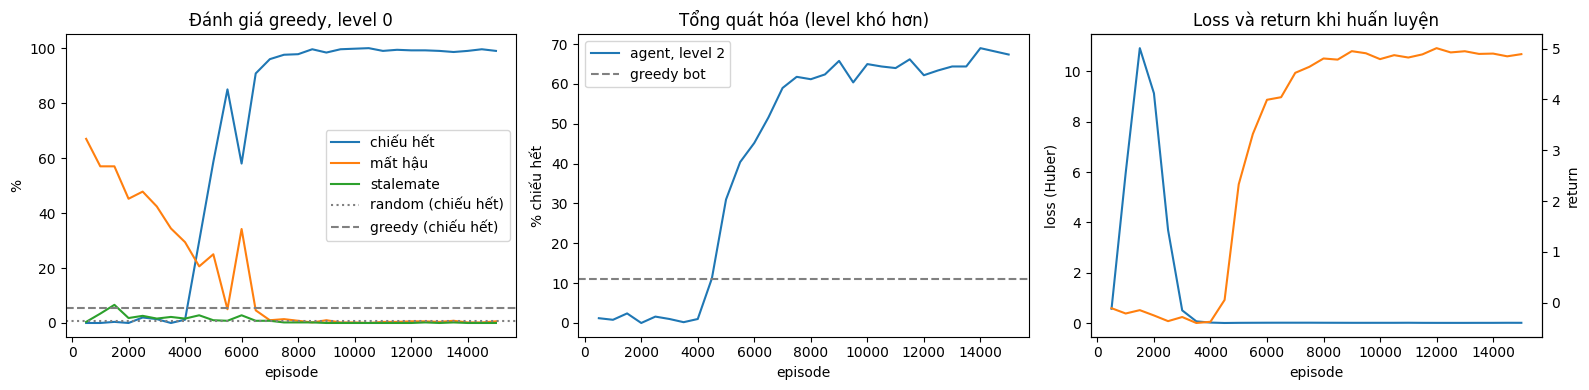

In [ ]:
def plot_history(history, baseline, cfg):
    if not history:
        print("Chưa có dữ liệu")
        return
    ep = [h["episode"] for h in history]
    fig, ax = plt.subplots(1, 3, figsize=(16, 4))

    ax[0].plot(ep, [h["eval_checkmate"] * 100 for h in history], label="chiếu hết")
    ax[0].plot(ep, [h["eval_queen_loss"] * 100 for h in history], label="mất hậu")
    ax[0].plot(ep, [h["eval_stalemate"] * 100 for h in history], label="stalemate")
    for name, style in (("random_policy", ":"), ("greedy_policy", "--")):
        s = baseline.get((name, cfg["eval_level"]))
        if s:
            ax[0].axhline(s["checkmate_rate"] * 100, linestyle=style, color="gray",
                          label=f"{name.replace('_policy','')} (chiếu hết)")
    ax[0].set_title(f"Đánh giá greedy, level {cfg['eval_level']}")
    ax[0].set_xlabel("episode"); ax[0].set_ylabel("%"); ax[0].legend()

    ax[1].plot(ep, [h["extra_checkmate"] * 100 for h in history], label=f"agent, level {cfg['extra_eval_level']}")
    s = baseline.get(("greedy_policy", cfg["extra_eval_level"]))
    if s:
        ax[1].axhline(s["checkmate_rate"] * 100, linestyle="--", color="gray", label="greedy bot")
    ax[1].set_title("Tổng quát hóa (level khó hơn)")
    ax[1].set_xlabel("episode"); ax[1].set_ylabel("% chiếu hết"); ax[1].legend()

    ax[2].plot(ep, [h["loss"] for h in history], label="loss")
    ax[2].set_xlabel("episode"); ax[2].set_ylabel("loss (Huber)")
    ax2 = ax[2].twinx()
    ax2.plot(ep, [h["train_return"] for h in history], color="tab:orange", label="return (train)")
    ax2.set_ylabel("return")
    ax[2].set_title("Loss và return khi huấn luyện")

    plt.tight_layout()
    plt.savefig(os.path.join(PROJECT_DIR, "training_curves.png"), dpi=150)
    plt.show()


plot_history(history, baseline, CONFIG)

In [ ]:
import pandas as pd

best_ck = torch.load(os.path.join(CKPT_DIR, "baseline_L0_best.pt"), map_location=device, weights_only=False)
best_net = QNet().to(device)
best_net.load_state_dict(best_ck["policy"])
print("Checkpoint tốt nhất: episode", best_ck["episode"], "| eval chiếu hết", f"{best_ck['eval_checkmate']:.1%}")

rows = []
env_f = kqk.KQKEnv(max_moves=CONFIG["max_moves"])
for level in (0, 1, 2):
    for name, pol in (("random", kqk.random_policy),
                      ("greedy_bot", kqk.greedy_policy),
                      ("DQN", make_agent_policy(best_net))):
        s = kqk.play_games(env_f, pol, n_games=500, level=level, seed=0)
        rows.append(dict(level=level, player=name,
                         checkmate=s["checkmate_rate"], queen_loss=s["queen_loss_rate"],
                         stalemate=s["stalemate_rate"], timeout=s["timeout_rate"],
                         mean_length=s["mean_length"], mean_reward=s["mean_reward"]))

df = pd.DataFrame(rows)
df.to_csv(os.path.join(PROJECT_DIR, "final_results.csv"), index=False)
df.style.format({"checkmate": "{:.1%}", "queen_loss": "{:.1%}", "stalemate": "{:.1%}",
                 "timeout": "{:.1%}", "mean_length": "{:.1f}", "mean_reward": "{:.2f}"})

Checkpoint tốt nhất: episode 10500 | eval chiếu hết 100.0%


,level,player,checkmate,queen_loss,stalemate,timeout,mean_length,mean_reward
0,0,random,0.8%,80.0%,6.4%,12.8%,22.0,-0.36
1,0,greedy_bot,5.0%,77.2%,3.8%,14.0%,22.7,-0.13
2,0,DQN,100.0%,0.0%,0.0%,0.0%,6.4,5.11
3,1,random,2.4%,76.2%,8.2%,13.2%,22.0,-0.38
4,1,greedy_bot,12.6%,71.0%,5.4%,11.0%,20.9,0.18
5,1,DQN,64.0%,17.4%,2.8%,14.0%,22.8,2.93
6,2,random,0.8%,76.4%,8.0%,14.8%,23.0,-0.45
7,2,greedy_bot,9.4%,73.0%,5.0%,12.6%,21.5,0.03
8,2,DQN,63.6%,16.6%,3.0%,14.8%,24.0,2.93
